# Modelo XGBoost — figuras para el capítulo de Resultados

Este notebook solo lee y grafica. No reentrena, no carga el modelo, no usa `X_test` ni `y_test` y no modifica ningún archivo de métricas. Todo sale de archivos ya guardados:

- `reports/xgboost/resultados_test.json`: bloques `subconjunto_comun_gru` (66,454 filas) y `test_completo` (66,544 filas);
- `reports/metrics/xgboost_comun.json`: métricas compartidas de XGBoost en el subconjunto común;
- `reports/xgboost/probabilidades_test.csv`: probabilidad predicha y clase real de cada flujo de la prueba completa;
- `reports/comparacion/test_resultadosSVM.json`: SVM en el subconjunto común;
- `reports/comparacion/test_resultadosGRU.json`: GRU en el subconjunto común, media y desviación estándar sobre 5 semillas.

**Por qué el subconjunto común.** El GRU necesita una ventana de flujos anteriores para clasificar cada flujo, así que no puede evaluar las 66,544 filas de la prueba. Los tres modelos se comparan en las 66,454 filas que sí evalúa el GRU (`idx_test_comun.npy`). La distribución de probabilidades de XGBoost (figura 3) usa la prueba completa porque no se compara con otros modelos.

**GRU.** El archivo trae tres variantes (`aleatorio_w10`, `baseline_w10`, `w1`). Se usa solo la indicada en `modelo_principal`, guardada en la constante `GRU_MODELO`. Sus valores son la media de 5 semillas, y sus barras de error, la desviación estándar.

Salidas en `reports/xgboost/figuras/`:

1. `comparacion_modelos.png`: recall, precisión, F1 y F2 de los tres modelos;
2. `errores_por_modelo.png`: falsos positivos y falsos negativos de cada modelo;
3. `distribucion_probabilidades.png`: histograma de la probabilidad de XGBoost por clase real.

In [1]:
import json
import sys
from math import isclose
from pathlib import Path

# Raíz del repo = primera carpeta hacia arriba que contenga src/.
RAIZ_REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ_REPO) not in sys.path:
    sys.path.append(str(RAIZ_REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.models.xgboost.model import UMBRAL_FINAL, apply_threshold

GRU_MODELO = "aleatorio_w10"  # variante principal del GRU; las demás del archivo se ignoran

RUTA_RESULTADOS_XGB = RAIZ_REPO / "reports" / "xgboost" / "resultados_test.json"
RUTA_METRICAS_COMUN = RAIZ_REPO / "reports" / "metrics" / "xgboost_comun.json"
RUTA_PROBABILIDADES = RAIZ_REPO / "reports" / "xgboost" / "probabilidades_test.csv"
RUTA_SVM = RAIZ_REPO / "reports" / "comparacion" / "test_resultadosSVM.json"
RUTA_GRU = RAIZ_REPO / "reports" / "comparacion" / "test_resultadosGRU.json"

FIGURAS_DIR = RAIZ_REPO / "reports" / "xgboost" / "figuras"
RUTA_FIG_COMPARACION = FIGURAS_DIR / "comparacion_modelos.png"
RUTA_FIG_ERRORES = FIGURAS_DIR / "errores_por_modelo.png"
RUTA_FIG_PROBABILIDADES = FIGURAS_DIR / "distribucion_probabilidades.png"


def leer_json(ruta):
    with open(ruta, encoding="utf-8") as f:
        return json.load(f)


resultados_xgb = leer_json(RUTA_RESULTADOS_XGB)
metricas_comun = leer_json(RUTA_METRICAS_COMUN)
svm = leer_json(RUTA_SVM)
gru = leer_json(RUTA_GRU)
probabilidades = pd.read_csv(RUTA_PROBABILIDADES)

xgb_comun = resultados_xgb["subconjunto_comun_gru"]
xgb_completo = resultados_xgb["test_completo"]

print(f"Python: {sys.executable}")
print(f"Umbral de XGBoost: {UMBRAL_FINAL} | variante GRU: {GRU_MODELO}")
print(f"probabilidades_test.csv: {probabilidades.shape[0]:,} filas, columnas {list(probabilidades.columns)}")

Python: C:\Users\Andy Ortega\Progras\Proyecto de Graduación\low-and-slow-ids\venv\Scripts\python.exe
Umbral de XGBoost: 0.87 | variante GRU: aleatorio_w10
probabilidades_test.csv: 66,544 filas, columnas ['probabilidad', 'label_binaria']


## Esquema de los archivos de SVM y GRU

Antes de usar los archivos de los otros modelos se verifica que tengan las claves esperadas. Si falta alguna, el notebook se detiene aquí.

In [2]:
CLAVES_SVM_METRICAS = {"accuracy", "precision", "recall", "f1", "f2", "tp", "fp", "fn", "tn", "roc_auc", "pr_auc"}
assert {"n_filas", "metricas", "ic95"} <= set(svm), f"Claves de SVM esperadas: n_filas, metricas, ic95 | obtenidas: {sorted(svm)}"
faltan = CLAVES_SVM_METRICAS - set(svm["metricas"])
assert not faltan, f"A metricas de SVM le faltan: {sorted(faltan)} | obtenidas: {sorted(svm['metricas'])}"
assert set(svm["ic95"]) == {"recall", "precision"}, f"ic95 de SVM esperado: recall, precision | obtenido: {sorted(svm['ic95'])}"
assert all(len(svm["ic95"][m]) == 2 for m in ("recall", "precision")), "Cada IC de SVM debe ser [lo, hi]"

assert gru["modelo_principal"] == GRU_MODELO, f"modelo_principal esperado: {GRU_MODELO} | obtenido: {gru['modelo_principal']}"
for bloque in ("media", "std"):
    assert GRU_MODELO in gru[bloque], f"El bloque {bloque} del GRU no contiene {GRU_MODELO}: {sorted(gru[bloque])}"
    faltan = {"recall", "precision", "f1", "f2", "fp", "fn"} - set(gru[bloque][GRU_MODELO])
    assert not faltan, f"Al bloque {bloque}[{GRU_MODELO}] le faltan: {sorted(faltan)}"

print("SVM:", {k: (sorted(v) if isinstance(v, dict) else v) for k, v in svm.items()})
print(f"GRU: modelo_principal = {gru['modelo_principal']} | variantes en media: {sorted(gru['media'])}")

SVM: {'archivo_indices': '..\\..\\results\\gru\\03_evaluacion_test\\idx_test_comun.npy', 'n_filas': 66454, 'umbral': -0.8319842314568479, 'metricas': ['accuracy', 'f1', 'f2', 'fn', 'fp', 'pr_auc', 'precision', 'recall', 'roc_auc', 'tasa_falsos_positivos', 'tn', 'tp'], 'ic95': ['precision', 'recall']}
GRU: modelo_principal = aleatorio_w10 | variantes en media: ['aleatorio_w10', 'baseline_w10', 'w1']


## Verificaciones antes de graficar

1. **Matriz de confusión de la prueba completa.** Se aplica el umbral 0.87 a `probabilidades_test.csv` con `apply_threshold()` (la misma función del modelo, `probabilidad >= umbral` es ataque) y se recalculan TP, FP, FN y TN. Deben dar 1164, 8, 11 y 65361, igual que `test_completo` en `resultados_test.json`.
2. **Métricas compartidas de XGBoost.** `xgboost_comun.json` y `subconjunto_comun_gru.metricas_umbral_principal` deben coincidir en recall, precisión, F1 y F2.
3. **Tamaño del subconjunto común.** SVM y GRU deben reportar 66,454 filas, y el GRU, 1,164 ataques; XGBoost debe reportar lo mismo en `subconjunto_comun_gru`.

Si un assert falla, el notebook se detiene y el mensaje muestra el valor esperado y el obtenido. Los datos no se corrigen para que pase.

In [3]:
# 1. Matriz de confusión recalculada desde las probabilidades guardadas
assert len(probabilidades) == xgb_completo["n"] == 66544, \
    f"Filas esperadas: 66544 | CSV: {len(probabilidades)} | JSON: {xgb_completo['n']}"
y_real = probabilidades["label_binaria"].to_numpy()
y_pred = apply_threshold(probabilidades["probabilidad"].to_numpy(), UMBRAL_FINAL)
recalculada = {
    "TP": int(((y_pred == 1) & (y_real == 1)).sum()),
    "FP": int(((y_pred == 1) & (y_real == 0)).sum()),
    "FN": int(((y_pred == 0) & (y_real == 1)).sum()),
    "TN": int(((y_pred == 0) & (y_real == 0)).sum()),
}
mc_json = xgb_completo["metricas_umbral_principal"]["matriz_confusion"]
desde_json = {"TP": mc_json["verdaderos_positivos"], "FP": mc_json["falsos_positivos"],
              "FN": mc_json["falsos_negativos"], "TN": mc_json["verdaderos_negativos"]}
esperada = {"TP": 1164, "FP": 8, "FN": 11, "TN": 65361}
assert recalculada == esperada, f"Esperado: {esperada} | recalculado desde el CSV: {recalculada}"
assert desde_json == esperada, f"Esperado: {esperada} | test_completo en resultados_test.json: {desde_json}"
print(f"1. Prueba completa con umbral {UMBRAL_FINAL}: {recalculada} (coincide con test_completo)")

# 2. xgboost_comun.json frente a subconjunto_comun_gru
metricas_xgb = xgb_comun["metricas_umbral_principal"]
pares = {"recall": "recall", "precision": "precision", "f1": "f1_score", "f2": "f2_score"}
for nombre, clave_comun in pares.items():
    a, b = metricas_xgb[nombre], metricas_comun[clave_comun]
    assert isclose(a, b, rel_tol=0, abs_tol=1e-12), \
        f"{nombre}: subconjunto_comun_gru = {a} | xgboost_comun.json[{clave_comun}] = {b}"
print("2. xgboost_comun.json coincide con subconjunto_comun_gru en recall, precisión, F1 y F2")

# 3. Tamaño del subconjunto común
assert svm["n_filas"] == 66454, f"SVM n_filas esperado: 66454 | obtenido: {svm['n_filas']}"
assert gru["n_filas"] == 66454, f"GRU n_filas esperado: 66454 | obtenido: {gru['n_filas']}"
assert gru["n_ataques"] == 1164, f"GRU n_ataques esperado: 1164 | obtenido: {gru['n_ataques']}"
assert xgb_comun["n"] == 66454 and xgb_comun["ataques"] == 1164, \
    f"XGBoost subconjunto común esperado: 66454 filas y 1164 ataques | obtenido: {xgb_comun['n']} y {xgb_comun['ataques']}"
print(f"3. Subconjunto común: SVM {svm['n_filas']:,} filas | GRU {gru['n_filas']:,} filas y {gru['n_ataques']:,} ataques "
      f"| XGBoost {xgb_comun['n']:,} filas y {xgb_comun['ataques']:,} ataques")

1. Prueba completa con umbral 0.87: {'TP': 1164, 'FP': 8, 'FN': 11, 'TN': 65361} (coincide con test_completo)
2. xgboost_comun.json coincide con subconjunto_comun_gru en recall, precisión, F1 y F2
3. Subconjunto común: SVM 66,454 filas | GRU 66,454 filas y 1,164 ataques | XGBoost 66,454 filas y 1,164 ataques


## Valores que se grafican

Se arma una sola tabla con todo lo que aparece en las figuras 1 y 2, leído de los archivos:

- **XGBoost:** valores de `subconjunto_comun_gru.metricas_umbral_principal`; IC 95 % bootstrap de `subconjunto_comun_gru.ic95_bootstrap.intervalos` para las cuatro métricas.
- **SVM:** valores de `metricas`; IC 95 % de `ic95`, que solo existe para recall y precisión. F1 y F2 quedan sin barra de error.
- **GRU:** media del bloque `media` y desviación estándar del bloque `std` (5 semillas), ambos de la variante `GRU_MODELO`.

Las barras de error se guardan como distancias por debajo y por encima del valor (`err_inf`, `err_sup`), que es lo que pide `matplotlib`.

In [4]:
MODELOS = ["XGBoost", "SVM", "GRU"]
METRICAS = ["recall", "precision", "f1", "f2"]
ETIQUETAS_METRICAS = {"recall": "Recall", "precision": "Precisión", "f1": "F1", "f2": "F2"}

filas = []
ic_xgb = xgb_comun["ic95_bootstrap"]["intervalos"]
for m in METRICAS:
    v = metricas_xgb[m]
    lo, hi = ic_xgb[m]
    filas.append(("XGBoost", m, v, v - lo, hi - v, "IC 95 % bootstrap"))
for m in METRICAS:
    v = svm["metricas"][m]
    if m in svm["ic95"]:
        lo, hi = svm["ic95"][m]
        filas.append(("SVM", m, v, v - lo, hi - v, "IC 95 %"))
    else:
        filas.append(("SVM", m, v, np.nan, np.nan, "sin IC"))
for m in METRICAS:
    v, s = gru["media"][GRU_MODELO][m], gru["std"][GRU_MODELO][m]
    filas.append(("GRU", m, v, s, s, "desv. estándar (5 semillas)"))

mc_xgb = metricas_xgb["matriz_confusion"]
errores = {
    "XGBoost": {"fp": mc_xgb["falsos_positivos"], "fn": mc_xgb["falsos_negativos"]},
    "SVM": {"fp": svm["metricas"]["fp"], "fn": svm["metricas"]["fn"]},
    "GRU": {"fp": gru["media"][GRU_MODELO]["fp"], "fn": gru["media"][GRU_MODELO]["fn"]},
}
errores_std = {"fp": gru["std"][GRU_MODELO]["fp"], "fn": gru["std"][GRU_MODELO]["fn"]}
for modelo in MODELOS:
    for m in ("fp", "fn"):
        s = errores_std[m] if modelo == "GRU" else np.nan
        filas.append((modelo, m, errores[modelo][m], s, s, "desv. estándar (5 semillas)" if modelo == "GRU" else "conteo"))

valores = pd.DataFrame(filas, columns=["modelo", "metrica", "valor", "err_inf", "err_sup", "barra_de_error"])

# Los conteos de errores deben coincidir con lo esperado para el capítulo de Resultados
esperados = {("XGBoost", "fp"): 8, ("XGBoost", "fn"): 11, ("SVM", "fp"): 28, ("SVM", "fn"): 12,
             ("GRU", "fp"): 131.2, ("GRU", "fn"): 31.8}
for (modelo, m), esperado in esperados.items():
    obtenido = errores[modelo][m]
    assert isclose(obtenido, esperado, abs_tol=1e-9), f"{modelo} {m.upper()} esperado: {esperado} | obtenido: {obtenido}"
for m, esperado in {"fp": 31.8, "fn": 12.4}.items():
    assert round(errores_std[m], 1) == esperado, f"GRU std {m.upper()} esperado: {esperado} | obtenido: {errores_std[m]:.4f}"

print(valores.to_string(index=False, float_format="{:.4f}".format))

 modelo   metrica    valor  err_inf  err_sup              barra_de_error
XGBoost    recall   0.9905   0.0060   0.0052           IC 95 % bootstrap
XGBoost precision   0.9931   0.0051   0.0043           IC 95 % bootstrap
XGBoost        f1   0.9918   0.0035   0.0034           IC 95 % bootstrap
XGBoost        f2   0.9911   0.0046   0.0041           IC 95 % bootstrap
    SVM    recall   0.9897   0.0076   0.0044                     IC 95 %
    SVM precision   0.9763   0.0104   0.0073                     IC 95 %
    SVM        f1   0.9829      NaN      NaN                      sin IC
    SVM        f2   0.9870      NaN      NaN                      sin IC
    GRU    recall   0.9727   0.0106   0.0106 desv. estándar (5 semillas)
    GRU precision   0.8967   0.0219   0.0219 desv. estándar (5 semillas)
    GRU        f1   0.9330   0.0106   0.0106 desv. estándar (5 semillas)
    GRU        f2   0.9563   0.0075   0.0075 desv. estándar (5 semillas)
XGBoost        fp   8.0000      NaN      NaN       

## Figura 1: comparación de métricas entre modelos

Barras agrupadas por métrica (recall, precisión, F1 y F2), con una barra por modelo. Todos los valores están en el subconjunto común de 66,454 flujos. El eje y está truncado en 0.85 para que se vean las diferencias; la etiqueta del eje lo indica. Encima de cada barra va su valor con 4 decimales, por arriba de la barra de error cuando la hay.

Colores: paleta categórica en orden fijo (azul, naranja, aqua), la misma de la figura de importancia del notebook 07.

Figura guardada en reports\xgboost\figuras\comparacion_modelos.png


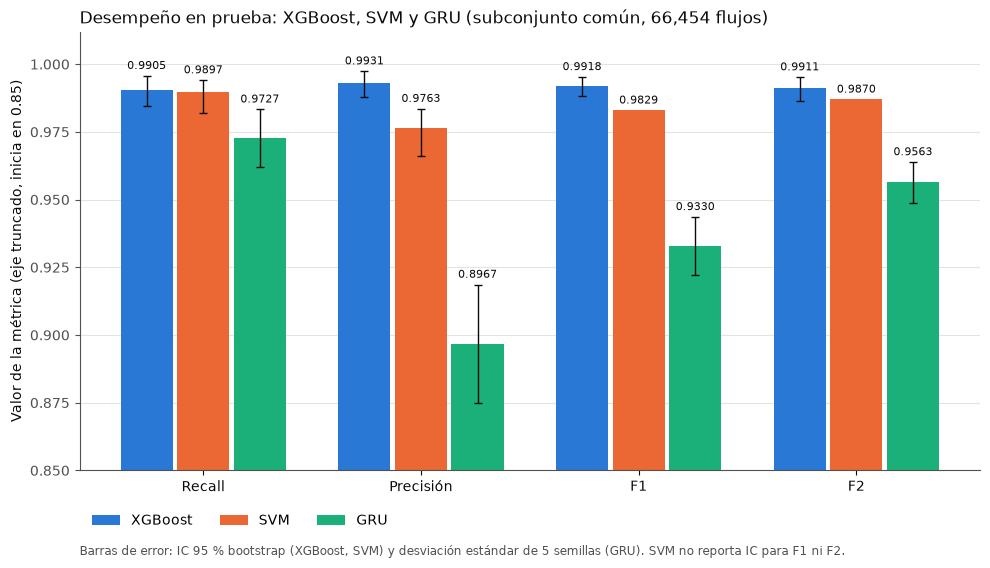

In [5]:
COLORES = {"XGBoost": "#2a78d6", "SVM": "#eb6834", "GRU": "#1baf7a"}  # paleta categórica: series 1, 2 y 3
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
Y_MIN = 0.85


def estilo_ejes(ax, eje_grilla="y"):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(TINTA_SUAVE)
    ax.tick_params(colors=TINTA_SUAVE)
    ax.grid(axis=eje_grilla, color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)


x = np.arange(len(METRICAS))
ancho = 0.26
fig, ax = plt.subplots(figsize=(10, 5.8))
for i, modelo in enumerate(MODELOS):
    sub = valores[valores["modelo"] == modelo].set_index("metrica").loc[METRICAS]
    pos = x + (i - 1) * ancho
    ax.bar(pos, sub["valor"] - Y_MIN, bottom=Y_MIN, width=ancho - 0.02, color=COLORES[modelo], label=modelo)
    con_error = sub["err_inf"].notna().to_numpy()
    ax.errorbar(pos[con_error], sub["valor"].to_numpy()[con_error],
                yerr=[sub["err_inf"].to_numpy()[con_error], sub["err_sup"].to_numpy()[con_error]],
                fmt="none", ecolor=TINTA, elinewidth=1, capsize=3)
    for p, v, e in zip(pos, sub["valor"], sub["err_sup"].fillna(0)):
        ax.annotate(f"{v:.4f}", xy=(p, v + e), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=TINTA)

ax.set_xticks(x, [ETIQUETAS_METRICAS[m] for m in METRICAS], color=TINTA)
ax.set_ylim(Y_MIN, 1.012)
ax.set_yticks(np.arange(Y_MIN, 1.0001, 0.025))
ax.set_ylabel(f"Valor de la métrica (eje truncado, inicia en {Y_MIN:.2f})", color=TINTA)
ax.set_title("Desempeño en prueba: XGBoost, SVM y GRU (subconjunto común, 66,454 flujos)", color=TINTA, loc="left")
estilo_ejes(ax)
ax.tick_params(axis="x", colors=TINTA)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.07))
ax.text(0, -0.17,
        "Barras de error: IC 95 % bootstrap (XGBoost, SVM) y desviación estándar de 5 semillas (GRU). "
        "SVM no reporta IC para F1 ni F2.",
        transform=ax.transAxes, fontsize=8.5, color=TINTA_SUAVE, ha="left", va="top")
plt.tight_layout()

FIGURAS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(RUTA_FIG_COMPARACION, dpi=200, bbox_inches="tight")
print(f"Figura guardada en {RUTA_FIG_COMPARACION.relative_to(RAIZ_REPO)}")
plt.show()

## Figura 2: falsos positivos y falsos negativos por modelo

Dos paneles: falsos positivos (benignos marcados como ataque) y falsos negativos (ataques no detectados), en el subconjunto común. Cada panel tiene su propia escala. XGBoost y SVM son un solo modelo evaluado, así que su valor es un conteo; el GRU es la media de 5 semillas, con la desviación estándar como barra de error y escrita junto al valor.

Figura guardada en reports\xgboost\figuras\errores_por_modelo.png


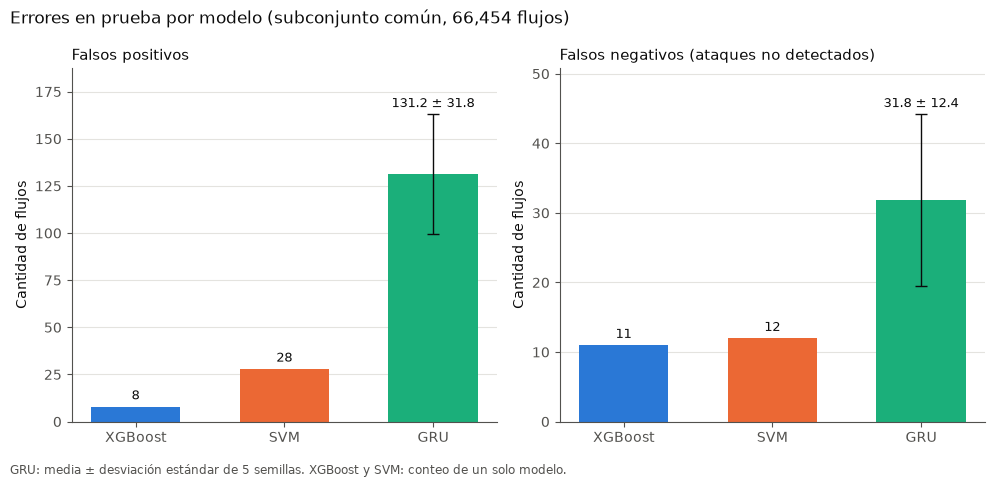

In [6]:
TITULOS_ERRORES = {"fp": "Falsos positivos", "fn": "Falsos negativos (ataques no detectados)"}

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, m in zip(ejes, ("fp", "fn")):
    alturas = [errores[modelo][m] for modelo in MODELOS]
    desv = [errores_std[m] if modelo == "GRU" else 0 for modelo in MODELOS]
    ax.bar(MODELOS, alturas, width=0.6, color=[COLORES[modelo] for modelo in MODELOS])
    ax.errorbar(["GRU"], [errores["GRU"][m]], yerr=[errores_std[m]], fmt="none", ecolor=TINTA, elinewidth=1, capsize=4)
    for modelo, h, s in zip(MODELOS, alturas, desv):
        texto = f"{h:.1f} ± {s:.1f}" if modelo == "GRU" else f"{h:.0f}"
        ax.annotate(texto, xy=(modelo, h + s), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color=TINTA)
    ax.set_ylim(0, max(h + s for h, s in zip(alturas, desv)) * 1.15)
    ax.set_title(TITULOS_ERRORES[m], color=TINTA, loc="left", fontsize=11)
    ax.set_ylabel("Cantidad de flujos", color=TINTA)
    ax.tick_params(axis="x", colors=TINTA)
    estilo_ejes(ax)

fig.suptitle("Errores en prueba por modelo (subconjunto común, 66,454 flujos)", color=TINTA, x=0.01, ha="left")
fig.text(0.01, -0.03, "GRU: media ± desviación estándar de 5 semillas. XGBoost y SVM: conteo de un solo modelo.",
         fontsize=8.5, color=TINTA_SUAVE, ha="left")
plt.tight_layout()
fig.savefig(RUTA_FIG_ERRORES, dpi=200, bbox_inches="tight")
print(f"Figura guardada en {RUTA_FIG_ERRORES.relative_to(RAIZ_REPO)}")
plt.show()

## Figura 3: distribución de la probabilidad predicha por XGBoost

Histograma de la probabilidad de ataque en la **prueba completa** (66,544 flujos), con 50 intervalos entre 0 y 1, separado por clase real. El eje y es logarítmico porque los benignos son unas 56 veces más que los ataques y casi todos se concentran cerca de 0. La línea punteada marca el umbral 0.87.

Los 11 ataques no detectados (`label_binaria == 1` y `probabilidad < 0.87`) se marcan con rayas cortas en el borde inferior para ubicar dónde cayó cada uno.

Figura guardada en reports\xgboost\figuras\distribucion_probabilidades.png


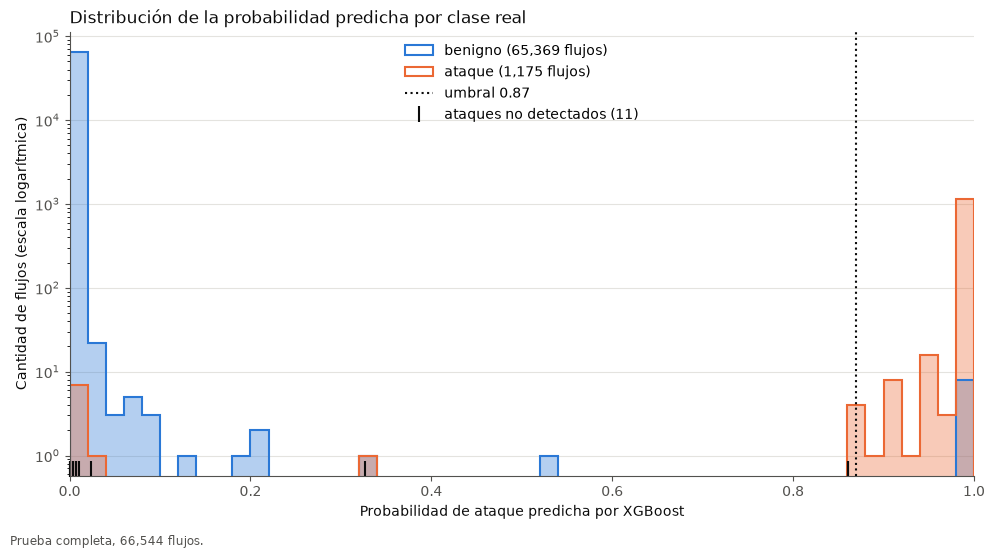

Probabilidad de los 11 ataques no detectados:
0.0000, 0.0001, 0.0042, 0.0067, 0.0071, 0.0073, 0.0105, 0.0239, 0.3268, 0.8608, 0.8608


In [7]:
benignos = probabilidades.loc[probabilidades["label_binaria"] == 0, "probabilidad"]
ataques = probabilidades.loc[probabilidades["label_binaria"] == 1, "probabilidad"]
no_detectados = ataques[ataques < UMBRAL_FINAL].sort_values()
assert len(no_detectados) == recalculada["FN"] == 11, \
    f"Ataques no detectados esperados: 11 | obtenidos: {len(no_detectados)}"

COLOR_BENIGNO, COLOR_ATAQUE = COLORES["XGBoost"], COLORES["SVM"]  # slots 1 y 2 de la paleta
intervalos = np.linspace(0, 1, 51)

fig, ax = plt.subplots(figsize=(10, 5.4))
for serie, color, nombre in ((benignos, COLOR_BENIGNO, "benigno"), (ataques, COLOR_ATAQUE, "ataque")):
    ax.hist(serie, bins=intervalos, histtype="stepfilled", color=color, alpha=0.35)
    ax.hist(serie, bins=intervalos, histtype="step", color=color, linewidth=1.5,
            label=f"{nombre} ({len(serie):,} flujos)")
ax.axvline(UMBRAL_FINAL, color=TINTA, linestyle=":", linewidth=1.5, label=f"umbral {UMBRAL_FINAL}")
ax.plot(no_detectados, np.full(len(no_detectados), 0.015), linestyle="none", marker="|", markersize=12,
        markeredgewidth=1.5, color=TINTA, transform=ax.get_xaxis_transform(), clip_on=False,
        label=f"ataques no detectados ({len(no_detectados)})")

ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("Probabilidad de ataque predicha por XGBoost", color=TINTA)
ax.set_ylabel("Cantidad de flujos (escala logarítmica)", color=TINTA)
ax.set_title("Distribución de la probabilidad predicha por clase real", color=TINTA, loc="left")
estilo_ejes(ax)
ax.legend(frameon=False, loc="upper center")
fig.text(0.01, -0.02, "Prueba completa, 66,544 flujos.", fontsize=8.5, color=TINTA_SUAVE, ha="left")
plt.tight_layout()
fig.savefig(RUTA_FIG_PROBABILIDADES, dpi=200, bbox_inches="tight")
print(f"Figura guardada en {RUTA_FIG_PROBABILIDADES.relative_to(RAIZ_REPO)}")
plt.show()

print("Probabilidad de los 11 ataques no detectados:")
print(", ".join(f"{p:.4f}" for p in no_detectados))

## Resumen

Tabla final con todos los valores graficados en las figuras 1 y 2, y los conteos de la figura 3.

In [8]:
tabla = valores.copy()
tabla["metrica"] = tabla["metrica"].map({**ETIQUETAS_METRICAS, "fp": "FP", "fn": "FN"})
tabla["ic_o_std"] = [
    "—" if pd.isna(ei) else (f"± {ei:.4f}" if modelo == "GRU" else f"[{v - ei:.4f}, {v + es:.4f}]")
    for modelo, v, ei, es in zip(tabla["modelo"], tabla["valor"], tabla["err_inf"], tabla["err_sup"])
]
tabla["valor"] = [f"{v:.4f}" if m not in ("FP", "FN") else (f"{v:.1f}" if modelo == "GRU" else f"{v:.0f}")
                  for modelo, m, v in zip(tabla["modelo"], tabla["metrica"], tabla["valor"])]

print("=" * 78)
print("RESUMEN — valores graficados (subconjunto común, 66,454 flujos)")
print("=" * 78)
print(tabla[["modelo", "metrica", "valor", "ic_o_std", "barra_de_error"]].to_string(index=False))
print()
print(f"Figura 3 (prueba completa, {len(probabilidades):,} flujos): benignos {len(benignos):,} | ataques {len(ataques):,} "
      f"| umbral {UMBRAL_FINAL} | ataques no detectados {len(no_detectados)}")
print(f"Matriz de confusión recalculada: {recalculada}")
print("Figuras: " + " | ".join(str(r.relative_to(RAIZ_REPO)) for r in
                                (RUTA_FIG_COMPARACION, RUTA_FIG_ERRORES, RUTA_FIG_PROBABILIDADES)))

RESUMEN — valores graficados (subconjunto común, 66,454 flujos)
 modelo   metrica  valor         ic_o_std              barra_de_error
XGBoost    Recall 0.9905 [0.9845, 0.9957]           IC 95 % bootstrap
XGBoost Precisión 0.9931 [0.9880, 0.9974]           IC 95 % bootstrap
XGBoost        F1 0.9918 [0.9883, 0.9953]           IC 95 % bootstrap
XGBoost        F2 0.9911 [0.9864, 0.9952]           IC 95 % bootstrap
    SVM    Recall 0.9897 [0.9821, 0.9941]                     IC 95 %
    SVM Precisión 0.9763 [0.9659, 0.9835]                     IC 95 %
    SVM        F1 0.9829                —                      sin IC
    SVM        F2 0.9870                —                      sin IC
    GRU    Recall 0.9727         ± 0.0106 desv. estándar (5 semillas)
    GRU Precisión 0.8967         ± 0.0219 desv. estándar (5 semillas)
    GRU        F1 0.9330         ± 0.0106 desv. estándar (5 semillas)
    GRU        F2 0.9563         ± 0.0075 desv. estándar (5 semillas)
XGBoost        FP      8  